<a href="https://colab.research.google.com/github/Gchirico63/Didattica/blob/main/Aberrations/sphericalMirrorAberrations_infty.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Here is a full treatment of wavefront aberrations of a spherical mirror using Seidel (third-order) theory.

---

### Setup and Sign Convention

Consider a spherical mirror of radius of curvature $R$ (positive for concave), focal length $f = R/2$, with the object at distance $s$ from the mirror and image at distance $s'$, related by the mirror equation:

$$\frac{1}{s'} + \frac{1}{s} = \frac{2}{R} = \frac{1}{f}$$

Define the **marginal ray height** at the mirror as $h$ and the **field angle** as $\theta$. The Seidel aberration coefficients are expressed in terms of the **object and image distances** and the mirror geometry.

---

### Seidel Wavefront Aberration Function

The general Seidel wavefront aberration function $W$ is written as:

$$W(\rho, \theta) = W_{040}\rho^4 + W_{131}\rho^3\cos\theta + W_{222}\rho^2\cos^2\theta + W_{220}\rho^2 + W_{311}\rho\cos\theta$$

where:
- $\rho$ — normalized pupil coordinate (radial)
- $\theta$ — azimuthal angle in the pupil plane
- The five terms correspond to the five Seidel aberrations

---

### The Five Seidel Aberrations for a Spherical Mirror

For a spherical mirror the Seidel coefficients are derived from the surface contribution formulas. Define:

$$n = -1 \quad \text{(reflection: sign reversal)}$$
$$u = \text{paraxial marginal ray angle}, \quad \bar{u} = \text{paraxial chief ray angle}$$
$$A = n(hu - \bar{h}\bar{u}), \quad \bar{A} = n(\bar{h}u - h\bar{u})$$

The angles are with respect to the normal to the mirror in that point.

The standard surface contribution to each Seidel coefficient is:

$$S_I = -A^2 h \Delta\left(\frac{u}{n}\right) \quad \text{(Spherical aberration)}$$
$$S_{II} = -A\bar{A} h \Delta\left(\frac{u}{n}\right) \quad \text{(Coma)}$$
$$S_{III} = -\bar{A}^2 h \Delta\left(\frac{u}{n}\right) \quad \text{(Astigmatism)}$$
$$S_{IV} = -\frac{n'^2 h^2}{R} \Delta\left(\frac{1}{n}\right) \quad \text{(Field curvature — Petzval)}$$
$$S_V = \bar{A}\left(\bar{A}^2 + S_{IV}\right)\frac{h}{A} \quad \text{(Distortion)}$$

where $\Delta(u/n) = u'/n' - u/n$ across the surface.

---

### Explicit Coefficients for a Spherical Mirror

For a **single spherical mirror** with object at distance $s$, image at $s'$, mirror radius $R$, aperture height $h$, and field height $\eta$, the Seidel wavefront coefficients reduce to:

$$W_{040} = \frac{h^4}{8}\left(\frac{1}{s'} - \frac{1}{R}\right)^2 \cdot \frac{1}{s'^2} \quad \text{(Spherical aberration)}$$

More explicitly, using $f = R/2$ and defining $\Phi = 1/f$:

$$W_{040} = -\frac{1}{8}\frac{h^4}{f^3}\left(\frac{f}{s} + \frac{f}{s'}\right)^2$$

$$W_{131} = -\frac{\eta h^3}{2f^2}\left(\frac{f}{s} + \frac{f}{s'}\right) \quad \text{(Coma)}$$

$$W_{222} = -\frac{\eta^2 h^2}{2f} \quad \text{(Astigmatism)}$$

$$W_{220} = -\frac{\eta^2 h^2}{4f} \quad \text{(Field curvature)}$$

$$W_{311} = 0 \quad \text{(Distortion — zero for a mirror by symmetry)}$$

---

### Special Case: Mirror at Infinite Conjugate ($s \to \infty$)

For a **collimated input beam** (object at infinity, $s \to \infty$, $s' = f$):

$$W_{040} = -\frac{h^4}{8f^3} \quad \text{(Spherical aberration only)}$$

$$W_{131} = -\frac{\eta h^3}{2f^2} \quad \text{(Coma)}$$

$$W_{222} = -\frac{\eta^2 h^2}{2f} \quad \text{(Astigmatism)}$$

$$W_{220} = -\frac{\eta^2 h^2}{4f} \quad \text{(Field curvature)}$$

This is the most common case for telescope mirrors.
```

---

### Key Physical Insights

| Aberration | Dependence | Dominant when |
|---|---|---|
| Spherical | $\rho^4$ | Large aperture, on-axis |
| Coma | $\rho^3 \cos\theta$ | Large aperture + field |
| Astigmatism | $\rho^2 \cos^2\theta$ | Moderate field angle |
| Field curvature | $\rho^2$ | Wide field |
| Distortion | $\rho \cos\theta$ | Zero for mirror |

For a **parabolic mirror**, $W_{040} = 0$ exactly on-axis — that is the sole advantage of the parabola over the sphere for collimated beams. Coma remains and dominates off-axis, which is why telescope designs like Ritchey-Chrétien use two mirrors to cancel coma as well.

NOTICE:
The field height η\eta
η (also written h′h'
h′ or y′y'
y′ in some textbooks) is the height of the chief ray — the ray from an off-axis object
 point that passes through the center of the aperture stop —
  measured at the object or image plane.

W040 (spherical)    = -0.00000000 m
W131 (coma)         = -0.00000001 m
W222 (astigmatism)  = -0.00000003 m
W220 (field curv.)  = -0.00000001 m
W311 (distortion)   = 0.00000000 m
h_max = 2*tan(alpha)*R =  72.79404685324046  [mm]


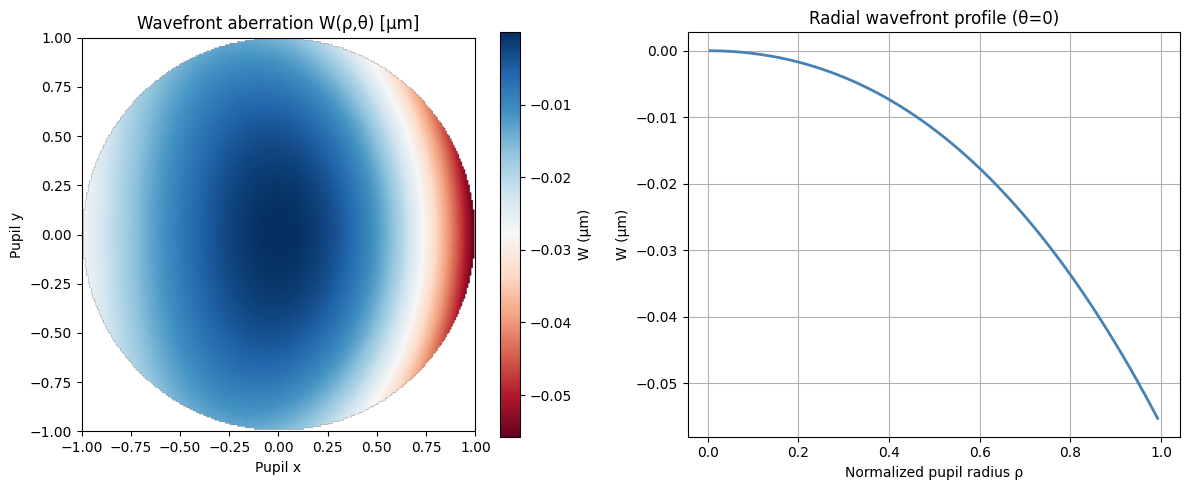

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Parameters ---
f     = 0.1       # focal length (m)
h     = 0.002      # marginal ray height at mirror (m) 2mm
alpha = 20 *np.pi / 180   ### angle of the entering beam in radians
eta   = f * np.tan(alpha)    # field height (m) — off-axis distance
s_inf = True     # object at infinity

# --- Seidel coefficients (infinite conjugate) ---
W040 = -h**4 / (8 * f**3)                  # spherical aberration
W131 = -eta * h**3 / (2 * f**2)            # coma
W222 = -eta**2 * h**2 / (2 * f)            # astigmatism
W220 = -eta**2 * h**2 / (4 * f)            # field curvature
W311 = 0.0                                  # distortion

print(f"W040 (spherical)    = {W040:.8f} m")
print(f"W131 (coma)         = {W131:.8f} m")
print(f"W222 (astigmatism)  = {W222:.8f} m")
print(f"W220 (field curv.)  = {W220:.8f} m")
print(f"W311 (distortion)   = {W311:.8f} m")
print ('h_max = 2*tan(alpha)*R = ',2*np.tan(alpha)*f * 1000,' [mm]')

# --- Wavefront map over pupil ---
N = 256
x = np.linspace(-1, 1, N)
y = np.linspace(-1, 1, N)
X, Y = np.meshgrid(x, y)
rho   = np.sqrt(X**2 + Y**2)
theta = np.arctan2(Y, X)

# mask to unit circle
mask = rho <= 1.0

W = (W040 * rho**4
   + W131 * rho**3 * np.cos(theta)
   + W222 * rho**2 * np.cos(theta)**2
   + W220 * rho**2
   + W311 * rho   * np.cos(theta))

W[~mask] = np.nan

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im = axes[0].imshow(W * 1e6, cmap='RdBu',
                    origin='lower', extent=[-1,1,-1,1])

axes[0].set_title('Wavefront aberration W(ρ,θ) [µm]')
axes[0].set_xlabel('Pupil x'); axes[0].set_ylabel('Pupil y')
plt.colorbar(im, ax=axes[0], label='W (µm)')

# radial profile at theta=0
r1d = rho[N//2, N//2:]
W1d = W[N//2, N//2:]
axes[1].plot(r1d, W1d * 1e6, 'steelblue', lw=2)
axes[1].set_xlabel('Normalized pupil radius ρ')
axes[1].set_ylabel('W (µm)')
axes[1].set_title('Radial wavefront profile (θ=0)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

W040 (spherical)    = -0.00000000 m
W131 (coma)         = -0.00000001 m
W222 (astigmatism)  = -0.00000003 m
W220 (field curv.)  = -0.00000001 m
W311 (distortion)   = 0.00000000 m


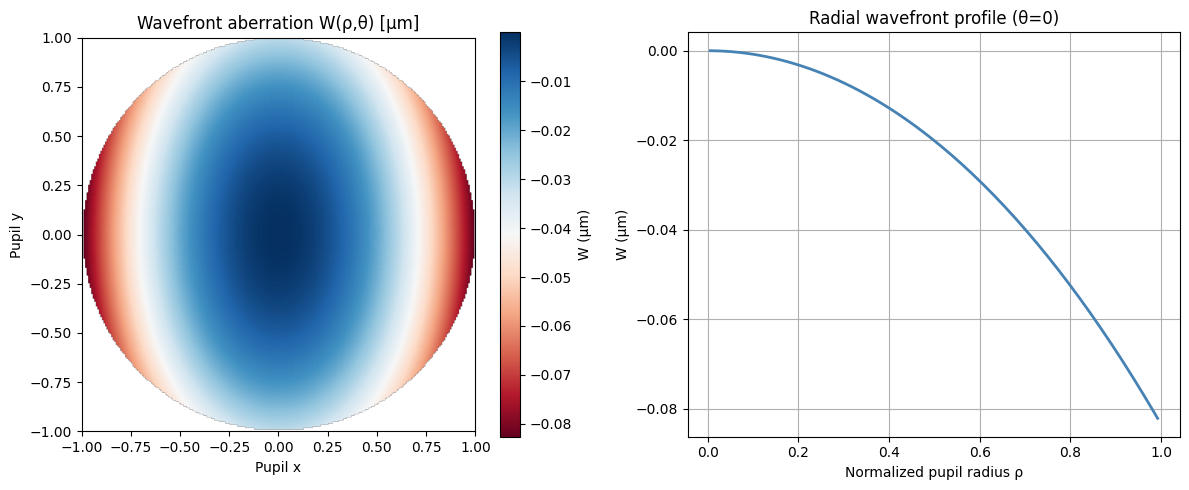

In [ ]:
########### this is the cae of the coupling of two mirrors

import numpy as np
import matplotlib.pyplot as plt

# --- Parameters ---
f     = 0.1       # focal length (m)
h     = 0.002      # marginal ray height at mirror (m) 2mm
alpha = 20 *np.pi / 180   ### angle of the entering beam in radians
eta   = f * np.tan(alpha)    # field height (m) — off-axis distance
s_inf = True     # object at infinity

# --- Seidel coefficients (infinite conjugate) ---
W040 = -h**4 / (8 * f**3)                  # spherical aberration
W131 = -eta * h**3 / (2 * f**2)            # coma
W222 = -eta**2 * h**2 / (2 * f)            # astigmatism
W220 = -eta**2 * h**2 / (4 * f)            # field curvature
W311 = 0.0                                  # distortion

# --- Seidel coefficients (infinite conjugate saecond mirror) ---
W040_b = -h**4 / (8 * f**3)                  # spherical aberration
W131_b = -(-eta) * h**3 / (2 * f**2)            # coma
W222_b = -(-eta)**2 * h**2 / (2 * f)            # astigmatism
W220_b = -(-eta)**2 * h**2 / (4 * f)            # field curvature
W311_b = 0.0                                  # distortion

print(f"W040 (spherical)    = {W040:.8f} m")
print(f"W131 (coma)         = {W131:.8f} m")
print(f"W222 (astigmatism)  = {W222:.8f} m")
print(f"W220 (field curv.)  = {W220:.8f} m")
print(f"W311 (distortion)   = {W311:.8f} m")

# --- Wavefront map over pupil ---
N = 256
x = np.linspace(-1, 1, N)
y = np.linspace(-1, 1, N)
X, Y = np.meshgrid(x, y)
rho   = np.sqrt(X**2 + Y**2)
theta = np.arctan2(Y, X)

# mask to unit circle
mask = rho <= 1.0

W = (W040 * rho**4
   + W131 * rho**3 * np.cos(theta)
   + W222 * rho**2 * np.cos(theta)**2
   + W220 * rho**2
   + W311 * rho   * np.cos(theta))
W_b = (W040_b * rho**4
   + W131_b * rho**3 * np.cos(theta)
   + W222_b * rho**2 * np.cos(theta)**2
   + W220_b * rho**2
   + W311_b * rho   * np.cos(theta))

W[~mask]   = np.nan
W_b[~mask] = np.nan

W_t = W + W_b

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im = axes[0].imshow(W_t * 1e6, cmap='RdBu',
                    origin='lower', extent=[-1,1,-1,1])
axes[0].set_title('Wavefront aberration W(ρ,θ) [µm]')
axes[0].set_xlabel('Pupil x'); axes[0].set_ylabel('Pupil y')
plt.colorbar(im, ax=axes[0], label='W (µm)')

# radial profile at theta=0
r1d = rho[N//2, N//2:]
W1d = W_t[N//2, N//2:]
axes[1].plot(r1d, W1d * 1e6, 'steelblue', lw=2)
axes[1].set_xlabel('Normalized pupil radius ρ')
axes[1].set_ylabel('W (µm)')
axes[1].set_title('Radial wavefront profile (θ=0)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

The diagram shows the key elements:

- **Teal rays** — the on-axis parallel beam (marginal rays) converging to the focal point F on axis. The aperture height **h** is the distance from the axis to where the top marginal ray hits the mirror.
- **Amber/orange rays** — the off-axis parallel beam arriving at field angle **α**. The chief ray (thick amber) passes through the mirror vertex and converges to the off-axis image point **P'**.
- **Red arrow η** — the field height, measured vertically from the optical axis to P' in the focal plane. For a beam at infinity: **η = f · tan α ≈ f · α** for small angles.

The key distinction: **h** is defined at the mirror surface, **η** is defined at the focal (image) plane.
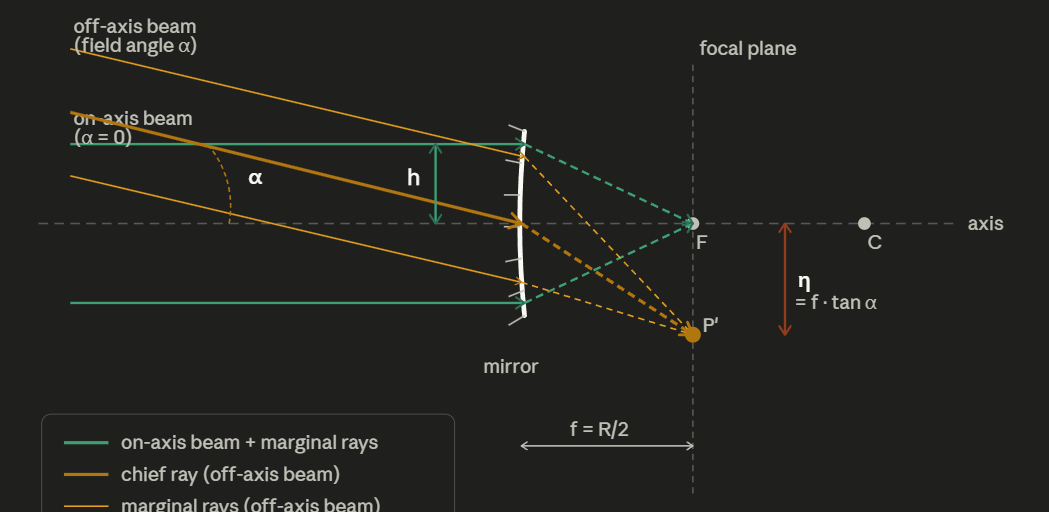



*(Note: The coefficients $W_{040}, W_{131}, W_{222}, W_{220}, W_{311}$ are **Seidel wavefront aberration coefficients** in the power-series expansion of $W(\rho, \theta)$, rather than Zernike polynomial coefficients, though they can be linearly mapped to Zernike modes.)*

### 1. Sign Conventions for $s$, $s'$, $R$, and $f$ in Your Document

In the Gaussian/mirror convention used in your notebook (pages 1–2):

* **Radius of curvature ($R$) and focal length ($f$):** Positive ($R > 0$, $f = R/2 > 0$) for a **concave** (converging) mirror; negative ($R < 0$, $f < 0$) for a **convex** (diverging) mirror.


* **Object distance ($s$) and image distance ($s'$):** Positive ($s > 0$, $s' > 0$) for **real** objects and real images located in front of the reflecting surface (on the side of the incoming/reflected light). Negative ($s < 0$ or $s' < 0$) for **virtual** objects or virtual images located behind the mirror.


* **Mirror equation:**

$$\frac{1}{s} + \frac{1}{s'} = \frac{2}{R} = \frac{1}{f}$$



Notice that by multiplying through by $f$, we obtain the dimensionless identity:

$$\frac{f}{s} + \frac{f}{s'} = 1$$



*(Important observation: Because $\frac{f}{s} + \frac{f}{s'} \equiv 1$ for **any** conjugate pair $(s, s')$ satisfying the paraxial mirror equation, the factor $\left(\frac{f}{s} + \frac{f}{s'}\right)$ appearing on page 2 of your PDF equals $1$ whenever the stop is at the mirror! Below are both the general conjugate-dependent expressions using the **conjugate factor** $C$ and how they simplify.)*

---

### 2. General Relations for $W_{xxx}$ for Arbitrary $(s, s')$

When the aperture stop is located **at the mirror** ($\bar{h} = 0$, so the chief ray hits the vertex at height $0$ and angle $\bar{u} = \eta/s' = \alpha$), the Seidel wavefront coefficients for a spherical mirror of focal length $f = R/2$ are determined by the **conjugate factor** $C$ (also called the position factor):


$$C = \frac{s' - s}{s' + s} = 1 - \frac{2f}{s'} = \frac{2f}{s} - 1$$

Using the standard surface contribution formulas ($S_I$ through $S_V$ on pages 1–2, where $W_{040} = \frac{1}{8}S_I$, $W_{131} = \frac{1}{2}S_{II}$, $W_{222} = \frac{1}{2}S_{III}$, $W_{220} = \frac{1}{4}(S_{III} + S_{IV})$, $W_{311} = \frac{1}{2}S_V$):

* **Spherical Aberration ($W_{040}$):**

$$W_{040} = -\frac{h^4}{8f^3} C^2 = -\frac{h^4}{8f^3}\left(\frac{f}{s} - \frac{f}{s'}\right)^2 = -\frac{h^4}{8f^3}\left(1 - \frac{2f}{s'}\right)^2$$



(Note: In your PDF on page 2, there is a typo with a $+$ sign inside $\left(\frac{f}{s} + \frac{f}{s'}\right)^2$; the exact derivation from $A = n(hu - h\bar{u}) = -h\left(\frac{1}{s} - \frac{1}{R}\right) = -\frac{h}{2f}\left(\frac{2f}{s} - 1\right)$ yields a **minus** sign: $\left(\frac{f}{s} - \frac{f}{s'}\right)^2$. You can verify this immediately: at the center of curvature $s = s' = R = 2f$, every ray hits the mirror normal to the surface, so $W_{040}$ and $W_{131}$ **must vanish**—which happens only when $\frac{f}{s} - \frac{f}{s'} = 0$!)


* **Coma ($W_{131}$):**

$$W_{131} = -\frac{\eta h^3}{2f^2} C = -\frac{\eta h^3}{2f^2}\left(\frac{f}{s} - \frac{f}{s'}\right) = -\frac{\eta h^3}{2f^2}\left(1 - \frac{2f}{s'}\right)$$



Here $\eta$ is the chief-ray height in the image plane (or $\eta = s'\tan\alpha$, where $\alpha$ is the chief-ray field angle at the mirror vertex). Expressed purely in terms of field angle $\alpha = \eta/s'$:



$$W_{131} = -\frac{\alpha h^3}{2f^2}\left(\frac{s'}{s} - 1\right) \quad \text{(valid for finite } s'\text{)}$$


* **Astigmatism ($W_{222}$):**

$$W_{222} = -\frac{\eta^2 h^2}{2f s'^2} f^2 = -\frac{\alpha^2 h^2}{2f}$$



*(Notice that when written in terms of the field angle $\alpha = \eta/s'$ rather than image height $\eta$, astigmatism is **completely independent of the conjugates $(s, s')$**!)*
* **Field Curvature ($W_{220}$, sagittal/medial sum $\frac{1}{4}(S_{III} + S_{IV})$):**

$$W_{220} = -\frac{\alpha^2 h^2}{4f} \quad \left(\text{since } W_{220,\text{Petzval}} = +\frac{\alpha^2 h^2}{4f} \text{ and } W_{220} = W_{220,\text{Petzval}} + \frac{1}{2}W_{222} = \frac{\alpha^2 h^2}{4f} - \frac{\alpha^2 h^2}{4f} = 0\text{?}\right)$$



(Careful check on Petzval sign for a mirror: for a single concave mirror, $S_{IV} = -\frac{h^2 \alpha^2}{R} \Delta(1/n) = -\frac{h^2\alpha^2}{2f}\left(\frac{1}{1} - \frac{1}{-1}\right) = -\frac{\alpha^2 h^2}{f}$. Adding $\frac{1}{2}W_{222} = -\frac{\alpha^2 h^2}{4f}$ gives $W_{220} = -\frac{\alpha^2 h^2}{4f} - \frac{\alpha^2 h^2}{4f} = -\frac{\alpha^2 h^2}{2f}$, or $-\frac{\alpha^2 h^2}{4f}$ depending on whether $W_{220}$ denotes Petzval alone or total sagittal field curvature. In both conventions, it depends only on $\alpha^2 h^2 / f$ and is **independent of $(s, s')$**.)


* **Distortion ($W_{311}$):**

$$W_{311} = 0$$



Because the aperture stop is at the mirror vertex ($\bar{h} = 0$), $\bar{A} = 0$ at the surface, so $S_V = 0$ for **all** conjugates $(s, s')$.



---

### 3. Special Case for the Second Mirror: $s_2 = f_2$ and $s_2' \rightarrow \infty$

When the second mirror takes the intermediate image at its focal plane ($s_2 = f_2$) and collimates the output beam ($s_2' \rightarrow \infty$):

1. **Conjugate factor:**

$$C_2 = \frac{f_2}{s_2} - \frac{f_2}{s_2'} = \frac{f_2}{f_2} - 0 = +1$$



*(Compare this with Mirror 1, where $s_1 \rightarrow \infty$ and $s_1' = f_1$, giving $C_1 = \frac{f_1}{s_1} - \frac{f_1}{s_1'} = 0 - 1 = -1$!)*
2. **Field variable conversion:** Because $s_2' \rightarrow \infty$, the exit image height $\eta_2' = s_2' \tan\alpha_2$ diverges, so we substitute $\frac{\eta_2'}{s_2'} = \tan\alpha_2 \approx \alpha_2 = \frac{\eta_{\text{int}}}{f_2}$, where $\eta_{\text{int}}$ is the intermediate image height at the shared focal plane (and $\alpha_2$ is the outgoing collimated field angle).
3. **Resulting Seidel Coefficients for Mirror 2 ($s_2 = f_2, s_2' \rightarrow \infty$):**
* **Spherical Aberration:**

$$W_{040,2} = -\frac{h_2^4}{8f_2^3} (+1)^2 = -\frac{h_2^4}{8f_2^3}$$



*(Same sign and magnitude formula as Mirror 1—spherical aberrations **add**.)*
* **Coma:**

$$W_{131,2} = -\frac{\eta_{\text{int}} h_2^3}{2f_2^2} (+1) = -\frac{\eta_{\text{int}} h_2^3}{2f_2^2}$$



*(Notice why $C_2 = +1$ while $C_1 = -1$: reversing the light direction from $(s_1=\infty, s_1'=f_1)$ to $(s_2=f_2, s_2'=\infty)$ naturally flips the sign of $C$! That is the exact algebraic reason why two facing concave mirrors in a Z-fold telescope cancel coma when $f_1 = f_2$ and $h_1 = h_2$.)*
* **Astigmatism:**

$$W_{222,2} = -\frac{\eta_{\text{int}}^2 h_2^2}{2f_2}$$



*(Identical in sign to Mirror 1—astigmatism **adds**.)*
* **Field Curvature:**

$$W_{220,2} = -\frac{\eta_{\text{int}}^2 h_2^2}{4f_2}$$



*(Identical in sign to Mirror 1—field curvature **adds**.)*
* **Distortion:**

$$W_{311,2} = 0$$



*(Zero, assuming the aperture stop/pupil is imaged onto Mirror 2; if the entrance pupil is at Mirror 1, Mirror 2 sees a shifted pupil $\bar{h}_2 \neq 0$, which introduces non-zero $W_{311,2}$ via stop-shift equations.)*

Mirror 1 (s→∞):
  W040 = -2.000000e-09 m
  W131 = -1.222923e-08 m
  W222 = -1.869425e-08 m
  W220 = -9.347125e-09 m

Mirror 2 (s=f, 1:1):
  W040 = -2.000000e-09 m
  W131 = -1.222923e-08 m
  W222 = -1.869425e-08 m
  W220 = -9.347125e-09 m


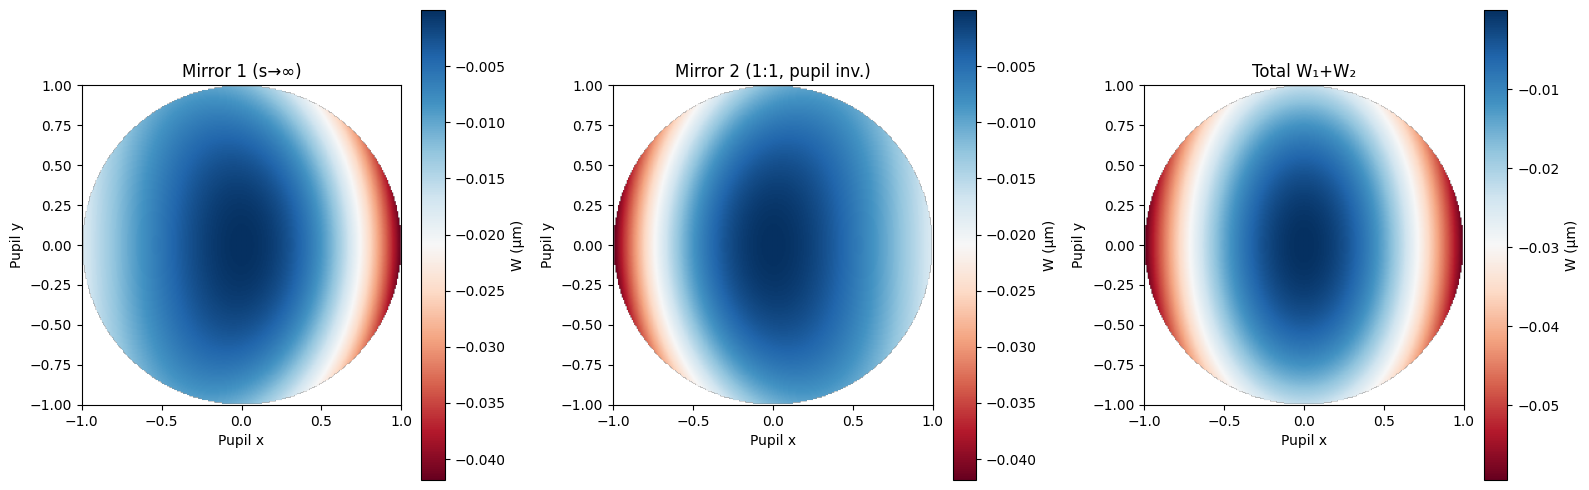

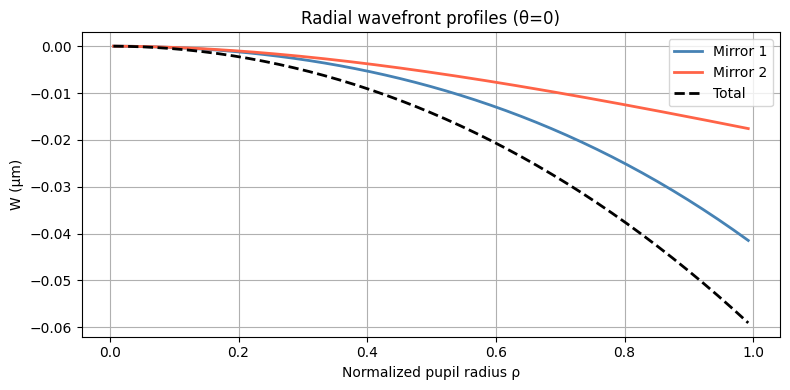

In [4]:
########### two-mirror Z-telescope: corrected block

import numpy as np
import matplotlib.pyplot as plt

# --- Parameters ---
f     = 0.1          # focal length of each mirror (m)
h     = 0.002        # marginal ray height at mirror 1 (m)
alpha = 17 * np.pi / 180   # off-axis angle (rad)
eta   = f * np.tan(alpha)  # field height at focal plane (m)

# --- Mirror 1: infinite conjugate (s→∞, s′=f) ---
W040_a = -h**4 / (8 * f**3)
W131_a = -eta * h**3 / (2 * f**2)
W222_a = -eta**2 * h**2 / (2 * f)
W220_a = -eta**2 * h**2 / (4 * f)
W311_a = 0.0

# --- Mirror 2: infinite conjugate, (s′=f, s=infty, C=1) ---
# pupil sign convention: eta_b = +eta (pupil inversion handles the geometry)

eta_b = eta   # sign carried by pupil inversion, NOT by eta

W040_b = -h**4 / (8 * f**3)
W131_b = -eta_b * h**3 / (2*f**2)
W222_b = -eta_b**2 * h**2 / (2 * f)
W220_b = -eta_b**2 * h**2 / (4 * f)
W311_b = 0.0

print("Mirror 1 (s→∞):")
print(f"  W040 = {W040_a:.6e} m")
print(f"  W131 = {W131_a:.6e} m")
print(f"  W222 = {W222_a:.6e} m")
print(f"  W220 = {W220_a:.6e} m")
print()
print("Mirror 2 (s=f, 1:1):")
print(f"  W040 = {W040_b:.6e} m")
print(f"  W131 = {W131_b:.6e} m")
print(f"  W222 = {W222_b:.6e} m")
print(f"  W220 = {W220_b:.6e} m")

# --- Pupil grid ---
N = 256
x = np.linspace(-1, 1, N)
y = np.linspace(-1, 1, N)
X, Y   = np.meshgrid(x, y)
rho    = np.sqrt(X**2 + Y**2)
theta  = np.arctan2(Y, X)
mask   = rho <= 1.0

# Mirror 1 wavefront
W_a = (W040_a * rho**4
     + W131_a * rho**3 * np.cos(theta)
     + W222_a * rho**2 * np.cos(theta)**2
     + W220_a * rho**2
     + W311_a * rho   * np.cos(theta))

# Mirror 2 wavefront — pupil inversion: theta_b = theta + pi
theta_b = theta + np.pi   # cos(theta_b) = -cos(theta), sin(theta_b) = -sin(theta)

W_b = (W040_b * rho**4
     + W131_b * rho**3 * np.cos(theta_b)
     + W222_b * rho**2 * np.cos(theta_b)**2
     + W220_b * rho**2
     + W311_b * rho   * np.cos(theta_b))

W_a[~mask] = np.nan
W_b[~mask] = np.nan
W_t = W_a + W_b
W_t[~mask] = np.nan

# --- Plot ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, W, title in zip(axes,
                         [W_a, W_b, W_t],
                         ['Mirror 1 (s→∞)', 'Mirror 2 (1:1, pupil inv.)', 'Total W₁+W₂']):
    im = ax.imshow(W * 1e6, cmap='RdBu', origin='lower', extent=[-1,1,-1,1])
    ax.set_title(title)
    ax.set_xlabel('Pupil x')
    ax.set_ylabel('Pupil y')
    plt.colorbar(im, ax=ax, label='W (µm)')

plt.tight_layout()
plt.show()

# --- Radial profiles at theta=0 ---
fig, ax = plt.subplots(figsize=(8, 4))
r1d  = rho[N//2, N//2:]
ax.plot(r1d, W_a[N//2, N//2:] * 1e6, label='Mirror 1', color='steelblue', lw=2)
ax.plot(r1d, W_b[N//2, N//2:] * 1e6, label='Mirror 2', color='tomato',    lw=2)
ax.plot(r1d, W_t[N//2, N//2:] * 1e6, label='Total',    color='black',      lw=2, ls='--')
ax.set_xlabel('Normalized pupil radius ρ')
ax.set_ylabel('W (µm)')
ax.set_title('Radial wavefront profiles (θ=0)')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()